# GAN - Generative Adversarial Network

In [9]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [10]:
# 1. Real data (Salary)
real_salary = np.random.randint(20000, 120000, (500, 1))  # 500 salaries

In [11]:
real_salary

array([[110609],
       [ 75821],
       [ 71785],
       [ 37514],
       [113969],
       [ 82390],
       [ 82543],
       [ 58273],
       [110674],
       [101462],
       [ 46235],
       [ 74326],
       [ 30277],
       [ 22966],
       [ 49373],
       [ 49491],
       [ 81167],
       [ 25777],
       [ 91394],
       [ 99204],
       [ 82450],
       [ 83854],
       [ 30104],
       [ 60598],
       [ 70642],
       [ 49667],
       [ 82441],
       [ 64260],
       [ 26074],
       [ 93811],
       [114183],
       [ 39132],
       [ 81895],
       [ 84842],
       [ 82307],
       [ 89319],
       [ 75806],
       [ 41155],
       [ 55826],
       [ 45726],
       [ 66612],
       [ 68099],
       [ 21536],
       [119547],
       [117635],
       [ 79284],
       [ 86003],
       [104004],
       [ 29910],
       [ 24520],
       [ 98603],
       [ 28903],
       [ 54648],
       [114321],
       [ 90846],
       [ 98611],
       [ 84823],
       [ 31754],
       [ 52542

In [12]:
# Normalize (0-9)
salary_min = real_salary.min()
salary_max = real_salary.max()
real_salary_norm = (real_salary - salary_min) / (salary_max - salary_min)

In [13]:
real_salary_norm

array([[9.08343786e-01],
       [5.59259445e-01],
       [5.18759721e-01],
       [1.74863278e-01],
       [9.42060107e-01],
       [6.25176860e-01],
       [6.26712157e-01],
       [3.83171943e-01],
       [9.08996036e-01],
       [8.16557122e-01],
       [2.62375194e-01],
       [5.44257689e-01],
       [1.02242737e-01],
       [2.88796347e-02],
       [2.93863830e-01],
       [2.95047915e-01],
       [6.12904521e-01],
       [5.70869500e-02],
       [7.15528574e-01],
       [7.93898951e-01],
       [6.25778937e-01],
       [6.39867543e-01],
       [1.00506748e-01],
       [4.06502433e-01],
       [5.07290151e-01],
       [2.96814008e-01],
       [6.25688626e-01],
       [4.43249210e-01],
       [6.00672320e-02],
       [7.39782249e-01],
       [9.44207516e-01],
       [1.91099293e-01],
       [6.20209724e-01],
       [6.49781747e-01],
       [6.24343987e-01],
       [6.94706738e-01],
       [5.59108926e-01],
       [2.11399328e-01],
       [3.58617229e-01],
       [2.57267573e-01],


In [14]:
# 2. Generator
G = Sequential([
    Dense(16, activation='relu', input_dim=1),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')  # output normalized salary
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
# 3. Discriminator
D = Sequential([
    Dense(16, activation='relu', input_dim=1),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
D.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [16]:
# 4. GAN
D.trainable = False # freezing the discriminatore weights
GAN = Sequential([G, D])
GAN.compile(optimizer='adam', loss='binary_crossentropy')

In [17]:
# 5. Train GAN
epochs = 2000
batch_size = 32

for epoch in range(epochs):
    # Train Discriminator
    idx = np.random.randint(0, real_salary_norm.shape[0], batch_size)
    real_batch = real_salary_norm[idx]

    noise = np.random.uniform(0, 1, (batch_size, 1))
    fake_batch = G.predict(noise, verbose=0)

    X = np.vstack([real_batch, fake_batch])
    y = np.vstack([np.ones((batch_size, 1)), np.zeros((batch_size, 1))])

    D.trainable = True
    D.train_on_batch(X, y)

    # Train Generator
    noise = np.random.uniform(0, 1, (batch_size, 1))
    y_gen = np.ones((batch_size, 1))
    D.trainable = False
    GAN.train_on_batch(noise, y_gen)

In [18]:
# 6. Generate Fake Salary Data
noise = np.random.uniform(0, 1, (10, 1))
fake_salary_norm = G.predict(noise, verbose=0)

In [19]:
# Denormalize
fake_salary = fake_salary_norm * (salary_max - salary_min) + salary_min

print("Fake Salary Data:")
print(fake_salary)

Fake Salary Data:
[[ 87494.69009894]
 [ 80839.714257  ]
 [ 50723.48425585]
 [ 65109.10743895]
 [ 47283.49164236]
 [109554.40682697]
 [ 85236.93377632]
 [103480.02065617]
 [ 43456.00662532]
 [ 91564.68641895]]


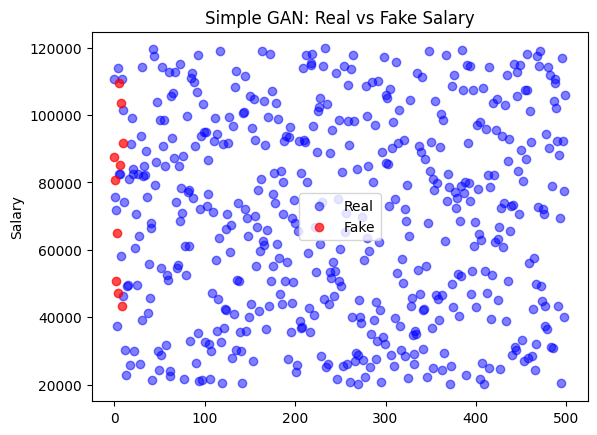

In [20]:
# 7. Plot
plt.scatter(np.arange(len(real_salary)), real_salary, color='blue', alpha=0.5, label='Real')
plt.scatter(np.arange(len(fake_salary)), fake_salary, color='red', alpha=0.7, label='Fake')
plt.ylabel('Salary')
plt.title('Simple GAN: Real vs Fake Salary')
plt.legend()
plt.show()